# RBC NOB cv12 캠페인 — Horn, Shishkina & Wagner (2013) JFM 724 의 Ra = 10⁶ ΔT 사다리 검증

ΔT = 20 · 40 · 60 K 를 **냉시작 + `viscous_coupling_number = 12`**(윗벽 D_× ≤ 12) 로 돌린 런(`stats_nob_cv12_dt*`, NOB 본런 프로토콜: 128×128×256, γ_z 2.6, CFL 0.3, t → 25000, 통계 16900~)과
OB 참조(`rbc_ob`, 같은 격자·Ra·Pr 의 상수물성: 본런 16900~27000 + 연장 27000~29000 의 확장통계)를 논문의 그림 번호 순서로 비교한다.

| 논문 | 양 | 출처 |
|---|---|---|
| fig.4 | ⟨T⟩(z), 정규화 2차미분 ~ (4.1) | 통계 프로파일 |
| fig.5(b) | χ_λθ, χ_λu vs ΔT | 헤더 lambda_theta/u (slope thickness (4.2)(4.3), rms 첫 극대 (4.21)(4.22)) |
| fig.6 | T_c vs ΔT (+ Wu&Libchaber·Zhang·Ahlers 모델, PaScaL_TCS) | 헤더 theta_c; 참조 csv |
| fig.7(b) | χ_Ra, χ_w, χ_Θ (4.14) | θ_c·λ·글리세롤 물성 다항식 후처리 |
| fig.8(b) | 시간평균 온도장의 체적 PDF | tpdf 3열(pdf_timemean; 구 형식은 순간 PDF 만) |
| fig.9(c,d)·11 | u_h,rms(z), w_rms(z), U_E(z) | 통계 프로파일 (주기 박스라 r 의존 풍속 프로파일은 없음) |
| fig.12(b)·13(b) | Re_pl, Re_E (ν_m, ν_c) vs ΔT, Re_NOB/Re_OB | 헤더 U_pl·U_E; OB 는 rbc_ob |
| fig.14(b) | Nu_NOB/Nu_OB = F_λ F_Δ (4.32) | λ·Δ·κ 후처리, λ_OB 는 rbc_ob |
| fig.15(b) | Nu vs ΔT, OB 점선 | 헤더 Nu_volume |

참조 숫자는 `horn2013_ra1e6_deltaT.csv`(그림에서 판독, ±0.05/±5%)와 `../../rbc/plot/{Horm,zhang,PaScaL_TCS}.csv`(θ_c·ΔT [K]). Horn 은 Γ=1 원통이라 절대값(특히 Re·Nu)은 우리 6×6 주기 박스와 다르고, **ΔT 경향과 NOB/OB 비**가 비교 대상이다.


In [1]:
import glob, os, re
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9.5, "legend.fontsize": 8})
APP = os.path.abspath(os.path.join(os.getcwd(), ".."))          # apps/rbc_nob
APPS = os.path.abspath(os.path.join(APP, ".."))                  # apps/
SAVE_DIR = os.environ.get("CV12_FIG_DIR")                         # 설정 시 PNG 저장 (배치 확인용)

# ── 케이스 ───────────────────────────────────────────────────────────────────
NOB_CASES = [  # (ΔT[K], stats dir, label)
    (20.0, f"{APP}/stats_nob_cv12_dt20", "dT=20K cv12"),
    (40.0, f"{APP}/stats_nob_cv12_dt40", "dT=40K cv12"),
    (60.0, f"{APP}/stats_nob_cv12_dt60", "dT=60K cv12"),
]
FALLBACK = {40.0: f"{APP}/stats_nob_dt40_visc12"}   # cv12 런이 아직 없을 때 개발용 대체(10-09 visc12 재시작 창, 구 형식) — 경고 출력
OB_MAIN = f"{APPS}/rbc_ob/stats_ob_pr2547_z256"        # OB 본런 16900~27000 (Nu, λ, Re_E, 프로파일)
OB_EXT  = f"{APPS}/rbc_ob/stats_ob_pr2547_z256_ext"    # OB 연장 (U_pl·Re_pl, 시간평균 T PDF)
COLOR = {20.0: "tab:green", 40.0: "tab:blue", 60.0: "tab:red", "OB": "0.25"}

# ── 글리세롤 물성 다항식 (physics/properties.hpp 와 동일; 인자 t = T − T_m [K]) ───────
A = [1.2477e3, -4.789e-4, -0.3795e-6, 0, 0, 0]          # ρ
B = [2.5108e3, 22.511e-4, 0, 0, 0, 0]                    # c_p
C = [2.9351e-3, 3.863e-4, 0, 0, 0, 0]                    # Λ (열전도도)
D = [238.71e-6, -702.83e-4, 2393.1e-6, -6923.0e-8, 33131.3e-10, -71517.5e-12]  # ν 인자 (μ = ρ·d-poly)
def poly(k, t): return k[0] * (1 + t * (k[1] + t * (k[2] + t * (k[3] + t * (k[4] + t * k[5])))))
def rho(t):   return poly(A, t)
def nu(t):    return poly(D, t)                         # ν = μ/ρ = d-다항식
def kappa(t): return poly(C, t) / (rho(t) * poly(B, t)) # κ = Λ/(ρ c_p)
def alpha(t): return -A[0] * (A[1] + 2 * A[2] * t) / rho(t)   # −(1/ρ) dρ/dT

# ── 로더 ─────────────────────────────────────────────────────────────────────
def header_of(path):
    h = {}
    for l in open(path):
        if not l.startswith("#"): break
        h.update({k: float(v) for k, v in re.findall(r"(\w+)=([-+\d.eE]+)(?=[\s,;)]|$)", l)})
    return h
def load_stats(d):
    fs = sorted(glob.glob(f"{d}/rbc_nob_stats_*.dat"))
    if not fs: return None
    h = header_of(fs[-1]); a = np.loadtxt(fs[-1], comments="#")
    pr = dict(path=fs[-1], n_files=len(fs), h=h, z=a[:,0], T=a[:,1], u_rms=a[:,2], v_rms=a[:,3], w_rms=a[:,4], T_rms=a[:,5],
              wT=a[:,6], Nu_z=a[:,7], kappa=a[:,8], mu=a[:,9], ke=a[:,10])
    pr["uh_rms"] = np.sqrt(pr["u_rms"]**2 + pr["v_rms"]**2); pr["U_E"] = np.sqrt(np.maximum(pr["ke"], 0))
    return pr
def load_tpdf(d):
    fs = sorted(glob.glob(f"{d}/rbc_nob_tpdf_*.dat"))
    if not fs: return None
    a = np.loadtxt(fs[-1], comments="#")
    return dict(T=a[:,0], inst=a[:,1], mean=(a[:,2] if a.shape[1] >= 3 else None))

runs = []
for dT, d, label in NOB_CASES:
    pr = load_stats(d); fb = False
    if pr is None and dT in FALLBACK:
        pr = load_stats(FALLBACK[dT]); fb = pr is not None
        if fb: print(f"⚠ {label}: cv12 통계 없음 → 개발용 대체 {FALLBACK[dT]} (구 형식, 재시작 창)")
    if pr is None: print(f"[{label}] 통계 없음 — 건너뜀"); continue
    pr.update(dT=dT, label=label + (" [fallback]" if fb else ""), color=COLOR[dT], pdf=load_tpdf(os.path.dirname(pr["path"])))
    runs.append(pr)
ob = load_stats(OB_MAIN); ob_ext = load_stats(OB_EXT)
if ob: ob.update(dT=0.0, label="OB (rbc_ob)", color=COLOR["OB"], pdf=load_tpdf(OB_EXT) or load_tpdf(OB_MAIN))
for pr in runs + ([ob] if ob else []):
    h = pr["h"]; w = f"t {h.get('t_start', float('nan')):.0f}-{h['t']:.0f} (sum_dt {h.get('sum_dt', float('nan')):.0f})"
    print(f"[{pr['label']}] {os.path.basename(pr['path'])}  {w}  Nu={h['Nu_volume']:.3f} theta_c={h['theta_c']:+.4f} "
          f"chi_lth={h.get('chi_lambda_theta', float('nan')):.3f} chi_lu={h.get('chi_lambda_u', float('nan')):.3f} "
          f"Re_E_m={h.get('Re_E_m', float('nan')):.4f} Re_pl_m={h.get('Re_pl_m', float('nan')):.4f}")
if ob_ext: print(f"[OB ext] {os.path.basename(ob_ext['path'])}  Re_pl_m={ob_ext['h'].get('Re_pl_m', float('nan')):.4f}  U_pl={ob_ext['h'].get('U_pl', float('nan')):.3e}")

# ── 참조 ─────────────────────────────────────────────────────────────────────
horn = np.genfromtxt("horn2013_ra1e6_deltaT.csv", delimiter=",", names=True, comments="#")
ref_tc = {k: np.loadtxt(f"{APPS}/rbc/plot/{f}", delimiter=",") for k, f in (("Horn 2013", "Horm.csv"), ("Zhang 1997", "zhang.csv"), ("PaScaL_TCS", "PaScaL_TCS.csv"))}

# ── 후처리 지표 (Horn §4) ─────────────────────────────────────────────────────
def derived(pr, ob):
    h = pr["h"]; dT = pr["dT"]; tc = h["theta_c"]
    lam_t, lam_b = h["lambda_theta_t"], h["lambda_theta_b"]
    D_t, D_b = (tc + 0.5) * dT, (0.5 - tc) * dT                 # 온도 강하 [K] (4.5)
    tbar_t, tbar_b = dT * (tc - 0.5) / 2, dT * (tc + 0.5) / 2   # BL 평균 온도 (T_m 기준 K)
    Ra_t = alpha(tbar_t) * D_t * lam_t**3 / (kappa(tbar_t) * nu(tbar_t)); Ra_b = alpha(tbar_b) * D_b * lam_b**3 / (kappa(tbar_b) * nu(tbar_b))
    w_t = alpha(tbar_t) * D_t * lam_t**2 / nu(tbar_t);           w_b = alpha(tbar_b) * D_b * lam_b**2 / nu(tbar_b)
    Th_t = kappa(tbar_t) * nu(tbar_t) / (alpha(tbar_t) * lam_t**3); Th_b = kappa(tbar_b) * nu(tbar_b) / (alpha(tbar_b) * lam_b**3)
    out = dict(chi_Delta=D_t / D_b if D_b else np.nan, chi_Ra=Ra_t / Ra_b, chi_w=w_t / w_b, chi_Theta=Th_t / Th_b)
    if ob:
        lam_ob = 0.5 * (ob["h"]["lambda_theta_b"] + ob["h"]["lambda_theta_t"])
        k_t, k_b, k_m = kappa(-dT / 2), kappa(+dT / 2), kappa(0.0)   # 판 온도의 κ (4.30)
        out["F_lambda"] = 2 * lam_ob / (lam_t + lam_b); out["F_Delta"] = (k_t * D_t + k_b * D_b) / (k_m * dT)
        out["Nu_ratio"] = h["Nu_volume"] / ob["h"]["Nu_volume"]
        for key in ("Re_E_m", "Re_E_c"):
            out[key + "_ratio"] = h.get(key, np.nan) / ob["h"][key] if ob["h"].get(key) else np.nan
        ob_pl = (ob_ext or {}).get("h", {}).get("Re_pl_m")
        for key in ("Re_pl_m", "Re_pl_c"):
            out[key + "_ratio"] = h.get(key, np.nan) / ob_pl if ob_pl else np.nan
    return out
for pr in runs: pr["d"] = derived(pr, ob)
dTs = np.array([pr["dT"] for pr in runs])
def col(key, src="h"): return np.array([pr[src].get(key, np.nan) for pr in runs], dtype=float)


[dT=20K cv12] rbc_nob_stats_03013097.dat  t 16900-25000 (sum_dt 8100)  Nu=10.092 theta_c=+0.0868 chi_lth=1.409 chi_lu=1.514 Re_E_m=0.0856 Re_pl_m=0.5253
[dT=40K cv12] rbc_nob_stats_06868050.dat  t 16900-25000 (sum_dt 8100)  Nu=9.597 theta_c=+0.1385 chi_lth=1.739 chi_lu=2.103 Re_E_m=0.0932 Re_pl_m=0.5142
[dT=60K cv12] rbc_nob_stats_12808149.dat  t 16900-18900 (sum_dt 2000)  Nu=9.379 theta_c=+0.1939 chi_lth=2.214 chi_lu=2.537 Re_E_m=0.1014 Re_pl_m=0.6314
[OB (rbc_ob)] rbc_nob_stats_00541175.dat  t 16900-27000 (sum_dt 10100)  Nu=9.878 theta_c=+0.0056 chi_lth=1.025 chi_lu=1.028 Re_E_m=0.0870 Re_pl_m=nan
[OB ext] rbc_nob_stats_00581175.dat  Re_pl_m=0.5317  U_pl=2.683e-02


## 0. 진행 모니터링과 수렴 판정 (모니터 로그)

`log/cv12_dt{20,40,60}_*.log` 의 모니터 행(step, t, dt, max|div|, θ_c, Nu(누적), T_min/max, Nu_b, Nu_t, D_×, u_bot_max, u_top_max, sec/step)을 읽는다.
- 이력: θ_c(순간), 벽 Nu 아래/위, dt 와 D_×(12 고정이어야 함), 벽 인접 max|U|(윗벽이 아랫벽보다 작아야 정상 — 스파이크면 수십 배), sec/step.
- 수렴: 1000 time 블록 평균의 θ_c·Nu_b·Nu_t 가 연속 블록 사이에서 **1% 안**에서 바뀌면 "정착"으로 본다(통계 시작 16900 앞에 정착해야 창이 깨끗하다).
- 통계 파일이 생기면 누적 파일별 Nu_volume·θ_c·χ_λθ·χ_λu 추이(누적 창이 길어질수록 수렴)도 같이 그린다.

[dT=20K] cv12_dt20_36135.log: t=24999/25000 (100.0%)  dt=0.00830 D_x=12.0  18.6 ms/step  1608 time/h  remaining ≈ 0.0 h  |  theta_c block 0.0866 (drift 0.26%)  Nu_wall block 10.099 (drift 0.00%)  u_top/u_bot max 2.1e-04/4.0e-04  →  정착  [통계 창 안]
[dT=40K] cv12_dt40_36135.log: t=25000/25000 (100.0%)  dt=0.00364 D_x=12.0  18.6 ms/step  704 time/h  remaining ≈ 0.0 h  |  theta_c block 0.1372 (drift 0.34%)  Nu_wall block 9.694 (drift 0.04%)  u_top/u_bot max 9.1e-05/5.8e-04  →  정착  [통계 창 안]
[dT=60K] cv12_dt60_36136.log: t=19428/25000 (77.7%)  dt=0.00148 D_x=12.0  18.1 ms/step  293 time/h  remaining ≈ 19.0 h  |  theta_c block 0.1935 (drift 0.07%)  Nu_wall block 9.546 (drift 0.16%)  u_top/u_bot max 4.0e-05/1.1e-03  →  정착  [통계 창 안]


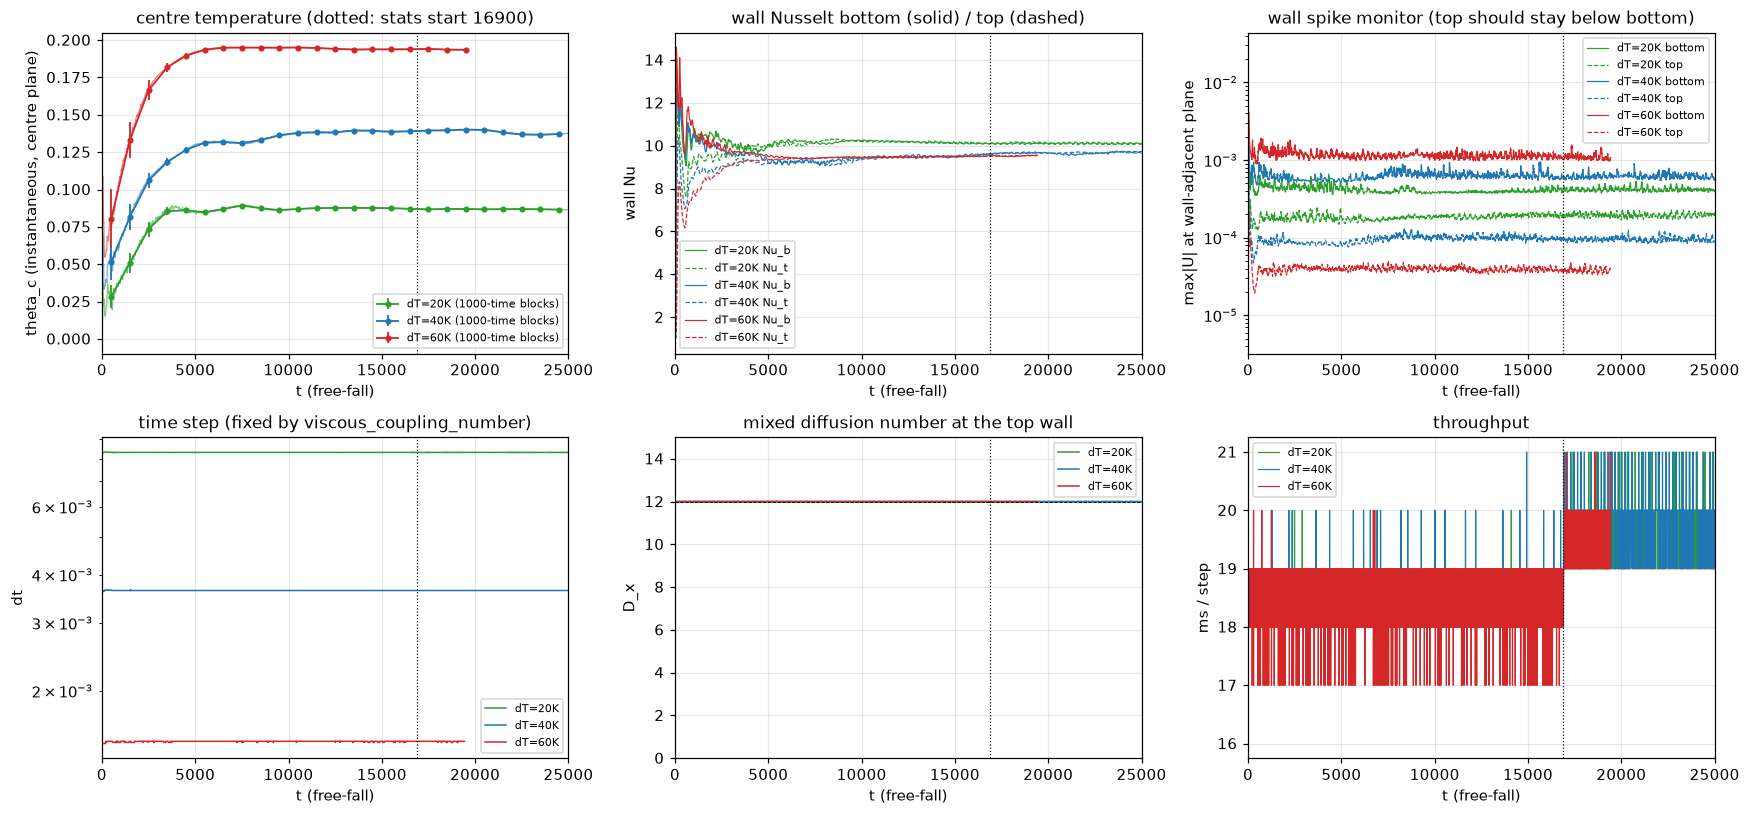

[dT=20K cv12] cumulative files 9: window 8100  Nu 10.0924  theta_c 0.08682  chi_lth 1.409  chi_lu 1.514  | change vs previous file: Nu +0.00%  theta_c +0.00%
[dT=40K cv12] cumulative files 9: window 8100  Nu 9.5966  theta_c 0.13852  chi_lth 1.739  chi_lu 2.103  | change vs previous file: Nu +0.00%  theta_c -0.01%
[dT=60K cv12] cumulative files 2: window 2000  Nu 9.3790  theta_c 0.19391  chi_lth 2.214  chi_lu 2.537  | change vs previous file: Nu +0.06%  theta_c -0.10%


/tmp/ipykernel_1433839/1900038215.py:75: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  a_.set_xlabel("accumulated time (sum_dt)"); a_.set_title(t); a_.legend(fontsize=7)


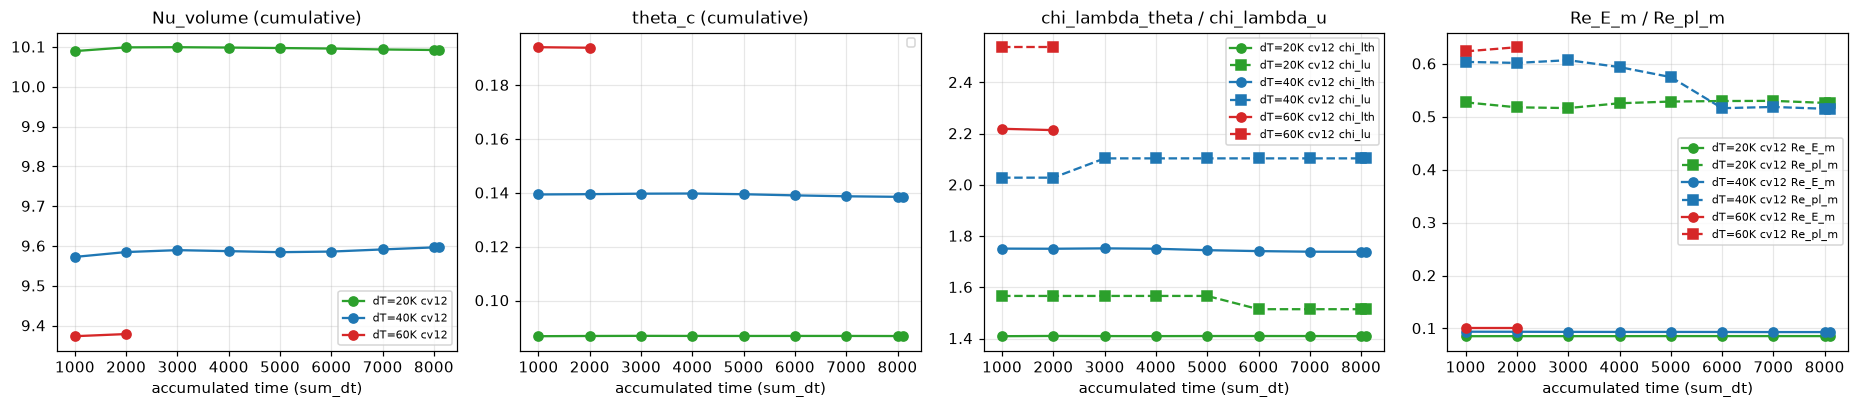

In [2]:
MON_CASES = [(20.0, f"{APP}/log/cv12_dt20_*.log"), (40.0, f"{APP}/log/cv12_dt40_*.log"), (60.0, f"{APP}/log/cv12_dt60_*.log")]
STATS_START, T_END, BLOCK = 16900.0, 25000.0, 1000.0
def read_monitor(pattern):
    fs = sorted(glob.glob(pattern), key=os.path.getmtime)
    if not fs: return None
    rows = [[float(v) for v in l.split()] for l in open(fs[-1]) if re.match(r"^\s*\d+\s", l) and len(l.split()) == 14]
    if not rows: return None
    d = np.array(rows)
    return dict(path=fs[-1], step=d[:,0], t=d[:,1], dt=d[:,2], div=d[:,3], theta_c=d[:,4], nu_run=d[:,5], nu_b=d[:,8], nu_t=d[:,9],
                dx=d[:,10], u_bot=d[:,11], u_top=d[:,12], spt=d[:,13])
def block_means(t, y, block=BLOCK):
    edges = np.arange(0, t.max() + block, block); out = []
    for a, b in zip(edges[:-1], edges[1:]):
        m = (t >= a) & (t < b)
        if m.sum() >= 5: out.append((0.5 * (a + b), y[m].mean(), y[m].std()))
    return np.array(out) if out else np.zeros((0, 3))
mons = {}
for dT, pat in MON_CASES:
    m = read_monitor(pat)
    if m is None: print(f"[dT={dT:.0f}K] 로그 없음 (아직 시작 전)"); continue
    mons[dT] = m
    t_now = m["t"][-1]; rate = (m["t"][-1] - m["t"][0]) / max(1e-9, (m["step"][-1] - m["step"][0]) * np.mean(m["spt"][1:]) / 3600)
    remaining = (T_END - t_now) / rate if rate > 0 else float("nan")
    bt, bn = block_means(m["t"], m["theta_c"]), block_means(m["t"], 0.5 * (m["nu_b"] + m["nu_t"]))
    drift_t = 100 * abs(bt[-1, 1] - bt[-2, 1]) / max(abs(bt[-1, 1]), 1e-9) if len(bt) >= 2 else float("nan")
    drift_n = 100 * abs(bn[-1, 1] - bn[-2, 1]) / max(abs(bn[-1, 1]), 1e-9) if len(bn) >= 2 else float("nan")
    settled = (drift_t < 1.0) and (drift_n < 1.0)
    print(f"[dT={dT:.0f}K] {os.path.basename(m['path'])}: t={t_now:.0f}/{T_END:.0f} ({100*t_now/T_END:.1f}%)  dt={m['dt'][-1]:.5f} D_x={m['dx'][-1]:.1f}  "
          f"{np.mean(m['spt'][1:])*1e3:.1f} ms/step  {rate:.0f} time/h  remaining ≈ {remaining:.1f} h  |  "
          f"theta_c block {bt[-1,1]:.4f} (drift {drift_t:.2f}%)  Nu_wall block {bn[-1,1]:.3f} (drift {drift_n:.2f}%)  "
          f"u_top/u_bot max {m['u_top'][-1]:.1e}/{m['u_bot'][-1]:.1e}  →  {'정착' if settled else '과도기'}"
          f"{'  [통계 창 안]' if t_now >= STATS_START else f'  [통계 시작까지 {(STATS_START - t_now)/rate:.1f} h]' if rate > 0 else ''}")

if mons:
    fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
    for dT, m in mons.items():
        c = COLOR[dT]; lab = f"dT={dT:.0f}K"
        ax[0,0].plot(m["t"], m["theta_c"], color=c, lw=0.8, alpha=0.6); bt = block_means(m["t"], m["theta_c"])
        if len(bt): ax[0,0].errorbar(bt[:,0], bt[:,1], yerr=bt[:,2], fmt="o-", color=c, ms=3, lw=1.2, label=f"{lab} (1000-time blocks)")
        ax[0,1].plot(m["t"], m["nu_b"], color=c, lw=0.8, label=f"{lab} Nu_b"); ax[0,1].plot(m["t"], m["nu_t"], color=c, lw=0.8, ls="--", label=f"{lab} Nu_t")
        ax[0,2].semilogy(m["t"], m["u_bot"], color=c, lw=0.8, label=f"{lab} bottom"); ax[0,2].semilogy(m["t"], m["u_top"], color=c, lw=0.8, ls="--", label=f"{lab} top")
        ax[1,0].semilogy(m["t"], m["dt"], color=c, lw=1.0, label=lab)
        ax[1,1].plot(m["t"], m["dx"], color=c, lw=1.0, label=lab)
        ax[1,2].plot(m["t"][1:], m["spt"][1:] * 1e3, color=c, lw=0.8, label=lab)
    for a in ax.flat: a.axvline(STATS_START, color="k", lw=0.8, ls=":"); a.set_xlabel("t (free-fall)"); a.set_xlim(0, T_END)
    for a in ax.flat: a.legend(fontsize=7)
    ax[0,0].set_ylabel("theta_c (instantaneous, centre plane)"); ax[0,0].set_title("centre temperature (dotted: stats start 16900)")
    ax[0,1].set_ylabel("wall Nu"); ax[0,1].set_title("wall Nusselt bottom (solid) / top (dashed)")
    ax[0,2].set_ylabel("max|U| at wall-adjacent plane"); ax[0,2].set_title("wall spike monitor (top should stay below bottom)")
    ax[1,0].set_ylabel("dt"); ax[1,0].set_title("time step (fixed by viscous_coupling_number)")
    ax[1,1].set_ylabel("D_x"); ax[1,1].set_ylim(0, 15); ax[1,1].axhline(12, color="k", lw=0.6, ls="--"); ax[1,1].set_title("mixed diffusion number at the top wall")
    ax[1,2].set_ylabel("ms / step"); ax[1,2].set_title("throughput")
    fig.tight_layout()
    if SAVE_DIR: fig.savefig(f"{SAVE_DIR}/cv12_monitor.png", dpi=90)
    plt.show()

# 누적 통계 파일별 추이 (통계 창에 들어온 케이스만)
hist = []
for dT, d, label in NOB_CASES:
    fs = sorted(glob.glob(f"{d}/rbc_nob_stats_*.dat"))
    if not fs: continue
    H = [header_of(f) for f in fs]
    hist.append((dT, label, np.array([[h["t"], h.get("sum_dt", np.nan), h["Nu_volume"], h["theta_c"], h.get("chi_lambda_theta", np.nan), h.get("chi_lambda_u", np.nan), h.get("Re_E_m", np.nan), h.get("Re_pl_m", np.nan)] for h in H])))
if hist:
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
    for dT, label, a in hist:
        c = COLOR[dT]
        ax[0].plot(a[:,1], a[:,2], "o-", color=c, label=label); ax[1].plot(a[:,1], a[:,3], "o-", color=c)
        ax[2].plot(a[:,1], a[:,4], "o-", color=c, label=f"{label} chi_lth"); ax[2].plot(a[:,1], a[:,5], "s--", color=c, label=f"{label} chi_lu")
        ax[3].plot(a[:,1], a[:,6], "o-", color=c, label=f"{label} Re_E_m"); ax[3].plot(a[:,1], a[:,7], "s--", color=c, label=f"{label} Re_pl_m")
        last = a[-1]; prev = a[-2] if len(a) > 1 else None
        print(f"[{label}] cumulative files {len(a)}: window {last[1]:.0f}  Nu {last[2]:.4f}  theta_c {last[3]:.5f}  chi_lth {last[4]:.3f}  chi_lu {last[5]:.3f}"
              + (f"  | change vs previous file: Nu {100*(last[2]/prev[2]-1):+.2f}%  theta_c {100*(last[3]/prev[3]-1):+.2f}%" if prev is not None else ""))
    for a_, t in zip(ax, ("Nu_volume (cumulative)", "theta_c (cumulative)", "chi_lambda_theta / chi_lambda_u", "Re_E_m / Re_pl_m")):
        a_.set_xlabel("accumulated time (sum_dt)"); a_.set_title(t); a_.legend(fontsize=7)
    fig.tight_layout()
    if SAVE_DIR: fig.savefig(f"{SAVE_DIR}/cv12_stats_history.png", dpi=90)
    plt.show()
else:
    print("통계 파일 아직 없음 — 통계 창(16900~)에 들어오면 누적 추이가 여기 그려진다")


## fig.4 — 평균 온도 프로파일과 정규화 2차미분 ~ = (∂²⟨T⟩/∂z²)/max|∂²⟨T_OB⟩/∂z²| (4.1)

NOB 는 OB 보다 위로 휘어(θ_c > 0) 윗벽 근처 |~| < 1, 아랫벽 근처 |~| > 1 (Λ 의 온도 의존).

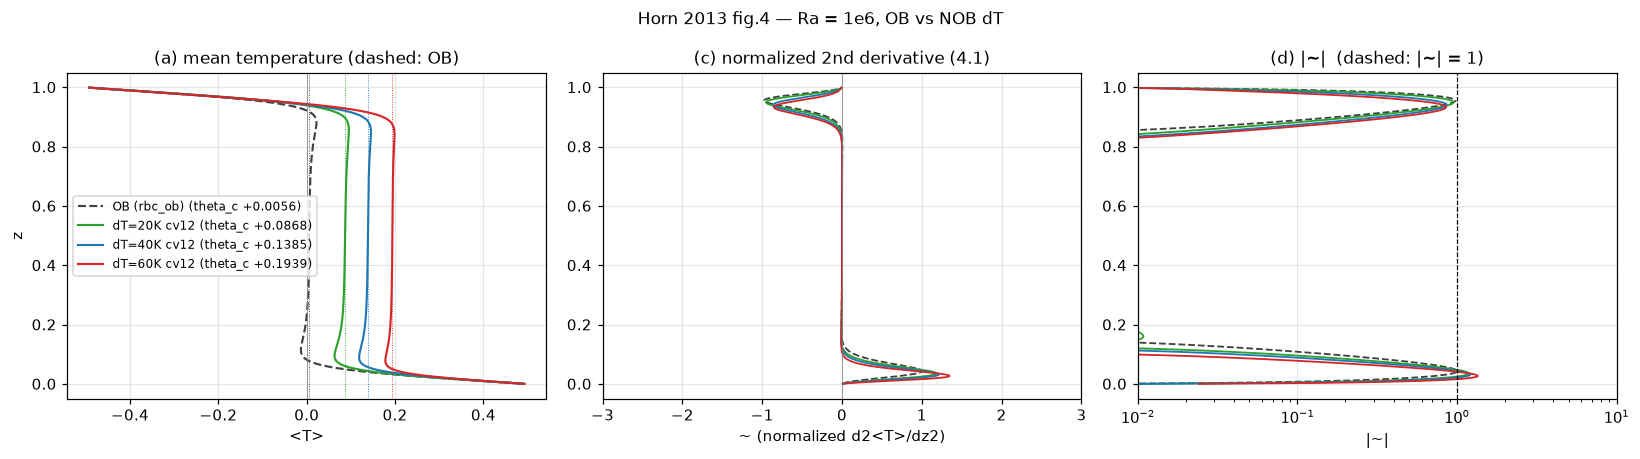

In [3]:
def second_derivative(z, T):
    d1 = np.gradient(T, z); return np.gradient(d1, z)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
norm = np.max(np.abs(second_derivative(ob["z"], ob["T"]))) if ob else 1.0
for pr in ([ob] if ob else []) + runs:
    ax[0].plot(pr["T"], pr["z"], color=pr["color"], lw=1.4, ls="--" if pr["dT"] == 0 else "-", label=f"{pr['label']} (theta_c {pr['h']['theta_c']:+.4f})")
    ax[0].axvline(pr["h"]["theta_c"], color=pr["color"], lw=0.6, ls=":")
    sd = second_derivative(pr["z"], pr["T"]) / norm
    ax[1].plot(sd, pr["z"], color=pr["color"], lw=1.2, ls="--" if pr["dT"] == 0 else "-")
    ax[2].plot(np.abs(sd), pr["z"], color=pr["color"], lw=1.2, ls="--" if pr["dT"] == 0 else "-")
ax[0].axvline(0, color="gray", lw=0.5); ax[0].set_xlabel("<T>"); ax[0].set_ylabel("z"); ax[0].legend(); ax[0].set_title("(a) mean temperature (dashed: OB)")
ax[1].axvline(0, color="gray", lw=0.5); ax[1].set_xlabel("~ (normalized d2<T>/dz2)"); ax[1].set_xlim(-3, 3); ax[1].set_title("(c) normalized 2nd derivative (4.1)")
ax[2].set_xscale("log"); ax[2].set_xlim(1e-2, 1e1); ax[2].axvline(1, color="k", lw=0.8, ls="--"); ax[2].set_xlabel("|~|"); ax[2].set_title("(d) |~|  (dashed: |~| = 1)")
fig.suptitle("Horn 2013 fig.4 — Ra = 1e6, OB vs NOB dT"); fig.tight_layout()
if SAVE_DIR: fig.savefig(f"{SAVE_DIR}/cv12_fig4.png", dpi=90)
plt.show()


## fig.5(b)·fig.6 — BL 두께 비 χ_λθ, χ_λu 와 중심온도 T_c vs ΔT

기호 = Horn 2013 판독값(Γ=1 원통); T_c 는 K 단위(θ_c·ΔT) 로 Horn·Zhang 실험·PaScaL_TCS 와 비교.

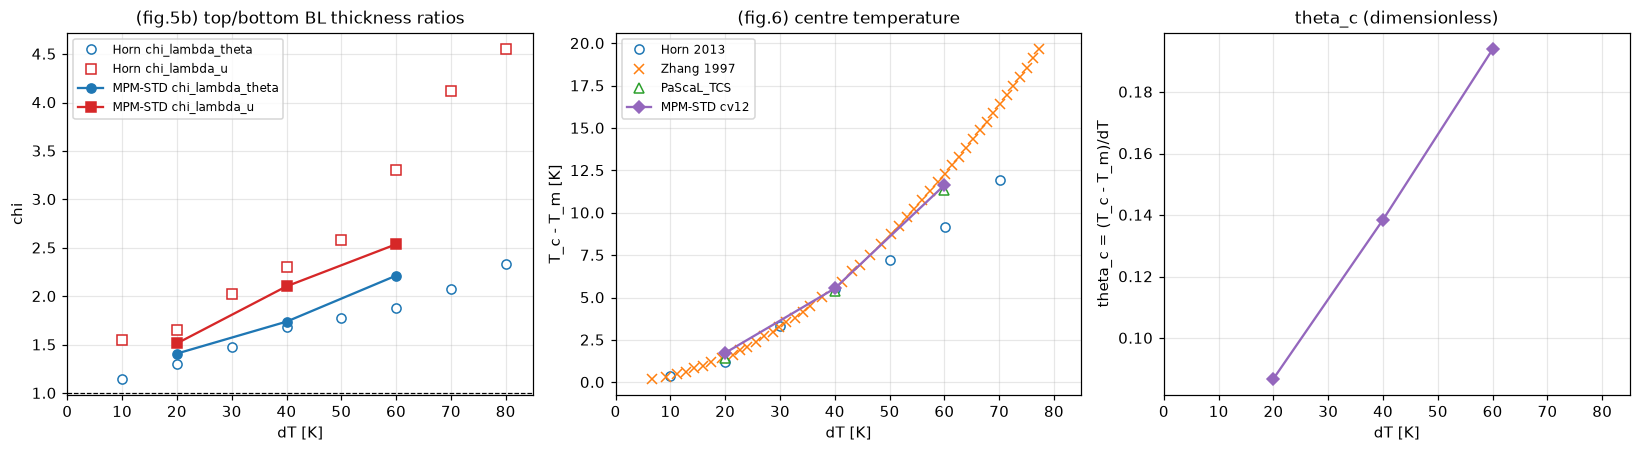

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(horn["deltaT"], horn["chi_lambda_theta"], "o", mfc="white", color="tab:blue", label="Horn chi_lambda_theta")
ax[0].plot(horn["deltaT"], horn["chi_lambda_u"], "s", mfc="white", color="tab:red", label="Horn chi_lambda_u")
ax[0].plot(dTs, col("chi_lambda_theta"), "o-", color="tab:blue", label="MPM-STD chi_lambda_theta")
ax[0].plot(dTs, col("chi_lambda_u"), "s-", color="tab:red", label="MPM-STD chi_lambda_u")
ax[0].axhline(1, color="k", lw=0.8, ls="--"); ax[0].set_xlabel("dT [K]"); ax[0].set_ylabel("chi"); ax[0].set_xlim(0, 85); ax[0].legend(); ax[0].set_title("(fig.5b) top/bottom BL thickness ratios")
for k, (name, arr) in enumerate(ref_tc.items()):
    ax[1].plot(arr[:,0], arr[:,1], ["o", "x", "^"][k], mfc="white", label=name)
ax[1].plot(dTs, col("theta_c") * dTs, "D-", color="tab:purple", label="MPM-STD cv12")
ax[1].set_xlabel("dT [K]"); ax[1].set_ylabel("T_c - T_m [K]"); ax[1].set_xlim(0, 85); ax[1].legend(); ax[1].set_title("(fig.6) centre temperature")
ax[2].plot(dTs, col("theta_c"), "D-", color="tab:purple"); ax[2].set_xlabel("dT [K]"); ax[2].set_ylabel("theta_c = (T_c - T_m)/dT"); ax[2].set_xlim(0, 85); ax[2].set_title("theta_c (dimensionless)")
fig.tight_layout()
if SAVE_DIR: fig.savefig(f"{SAVE_DIR}/cv12_fig5_6.png", dpi=90)
plt.show()


## fig.7(b) — BL 모델 가정의 점검: χ_Ra, χ_w, χ_Θ (4.11)~(4.14), 그리고 χ_Δ

BL 평균온도 (T_t+T_c)/2, (T_b+T_c)/2 의 α·ν·κ 와 측정 λ·Δ 로 계산. Horn: 글리세롤에서는 어느 것도 정확히 1 이 아님(χ_Θ 가 가장 1 에 가까움).

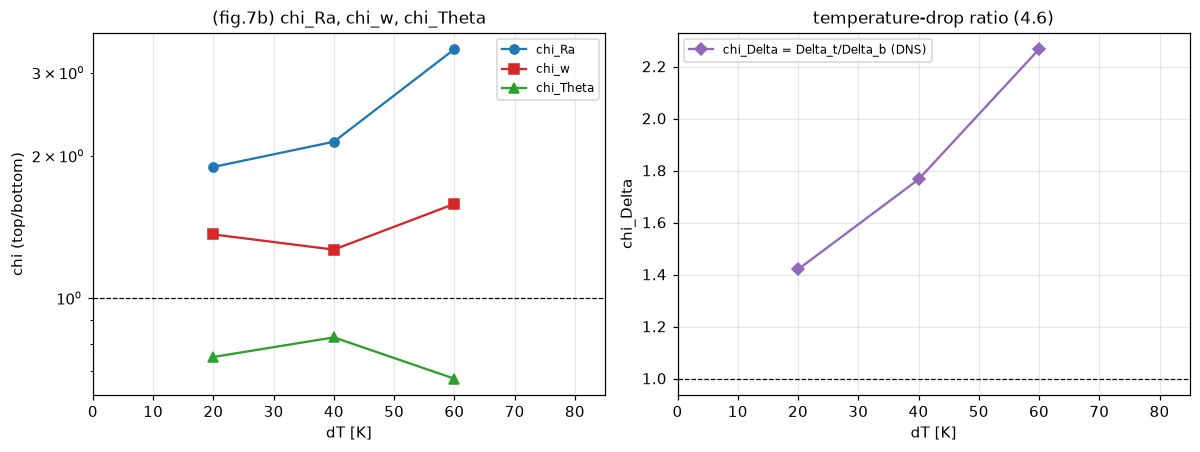

  dT chi_Delta   chi_Ra    chi_w chi_Theta F_lambda  F_Delta Nu_ratio
  20     1.420    1.894    1.363     0.750    1.024    1.003    1.022
  40     1.766    2.141    1.266     0.825    0.980    1.009    0.972
  60     2.267    3.361    1.581     0.675    0.968    1.020    0.949


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for key, mk, c in (("chi_Ra", "o", "tab:blue"), ("chi_w", "s", "tab:red"), ("chi_Theta", "^", "tab:green")):
    ax[0].semilogy(dTs, col(key, "d"), mk + "-", color=c, label=key)
ax[0].axhline(1, color="k", lw=0.8, ls="--"); ax[0].set_xlabel("dT [K]"); ax[0].set_ylabel("chi (top/bottom)"); ax[0].set_xlim(0, 85); ax[0].legend(); ax[0].set_title("(fig.7b) chi_Ra, chi_w, chi_Theta")
ax[1].plot(dTs, col("chi_Delta", "d"), "D-", color="tab:purple", label="chi_Delta = Delta_t/Delta_b (DNS)")
ax[1].axhline(1, color="k", lw=0.8, ls="--"); ax[1].set_xlabel("dT [K]"); ax[1].set_ylabel("chi_Delta"); ax[1].set_xlim(0, 85); ax[1].legend(); ax[1].set_title("temperature-drop ratio (4.6)")
fig.tight_layout()
if SAVE_DIR: fig.savefig(f"{SAVE_DIR}/cv12_fig7.png", dpi=90)
plt.show()
print(f"{'dT':>4} {'chi_Delta':>9} {'chi_Ra':>8} {'chi_w':>8} {'chi_Theta':>9} {'F_lambda':>8} {'F_Delta':>8} {'Nu_ratio':>8}")
for pr in runs:
    d = pr["d"]; print(f"{pr['dT']:4.0f} {d['chi_Delta']:9.3f} {d['chi_Ra']:8.3f} {d['chi_w']:8.3f} {d['chi_Theta']:9.3f} {d.get('F_lambda', np.nan):8.3f} {d.get('F_Delta', np.nan):8.3f} {d.get('Nu_ratio', np.nan):8.3f}")


## fig.8(b) — 시간평균 온도장의 체적 PDF (OB + NOB ΔT)

실선 = 시간평균 장의 PDF(논문 정의, 확장 통계), 점선 = 순간 온도의 PDF(구 정의). NOB 는 최빈값이 T_c 쪽으로 이동하고 비대칭.

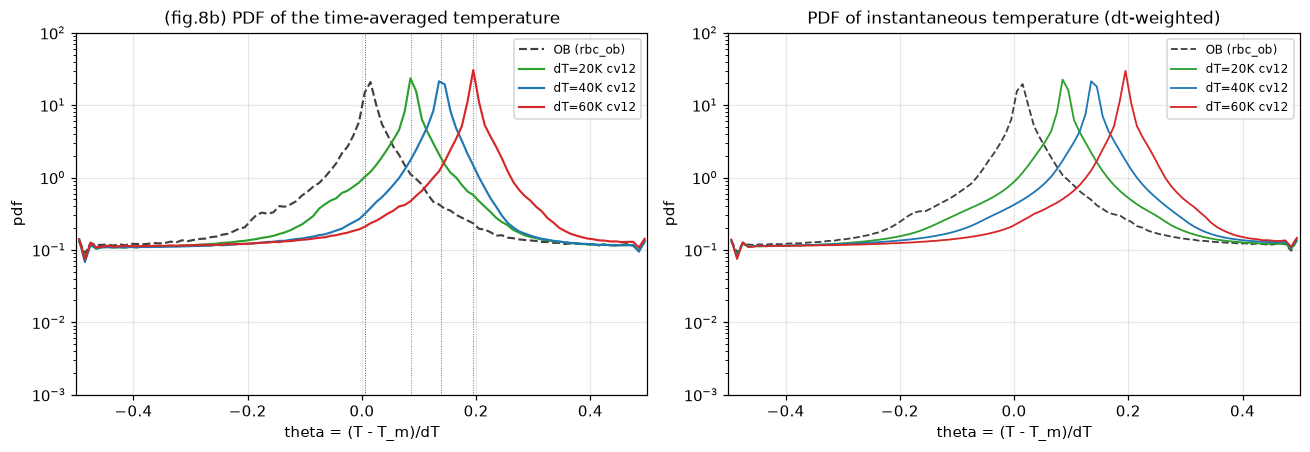

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for pr in ([ob] if ob else []) + runs:
    p = pr.get("pdf")
    if p is None: continue
    if p["mean"] is not None: ax[0].plot(p["T"], p["mean"], color=pr["color"], lw=1.4, ls="--" if pr["dT"] == 0 else "-", label=pr["label"])
    ax[1].plot(p["T"], p["inst"], color=pr["color"], lw=1.2, ls="--" if pr["dT"] == 0 else "-", label=pr["label"])
    ax[0].axvline(pr["h"]["theta_c"], color=pr["color"], lw=0.6, ls=":")
for a, t in zip(ax, ("(fig.8b) PDF of the time-averaged temperature", "PDF of instantaneous temperature (dt-weighted)")):
    a.set_xlabel("theta = (T - T_m)/dT"); a.set_ylabel("pdf"); a.set_xlim(-0.5, 0.5); a.set_yscale("log"); a.set_ylim(1e-3, 1e2); a.legend(); a.set_title(t)
fig.tight_layout()
if SAVE_DIR: fig.savefig(f"{SAVE_DIR}/cv12_fig8.png", dpi=90)
plt.show()


## fig.9(c,d)·fig.11 — 속도 rms 프로파일과 에너지 기반 풍속 U_E(z) (4.23)

주기 박스라 반경 방향 프로파일은 없고 z 프로파일만. 실선 아랫벽쪽·점선 윗벽쪽으로 접어 그린 패널은 NOB 비대칭(윗벽 μ̂ 큼 → 변동 작음)을 보여 준다.

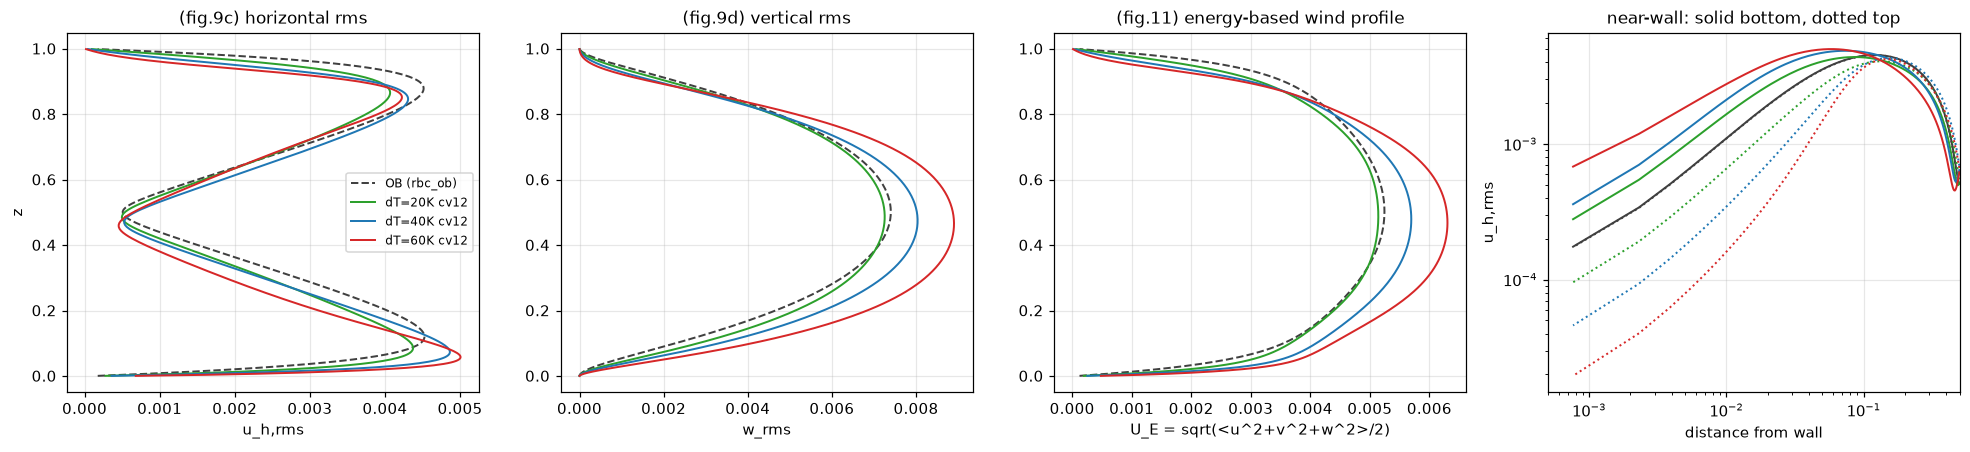

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
for pr in ([ob] if ob else []) + runs:
    ls = "--" if pr["dT"] == 0 else "-"; z = pr["z"]; nz = len(z)
    ax[0].plot(pr["uh_rms"], z, color=pr["color"], lw=1.3, ls=ls, label=pr["label"])
    ax[1].plot(pr["w_rms"], z, color=pr["color"], lw=1.3, ls=ls)
    ax[2].plot(pr["U_E"], z, color=pr["color"], lw=1.3, ls=ls)
    ax[3].loglog(z[:nz//2], pr["uh_rms"][:nz//2], color=pr["color"], lw=1.3)
    ax[3].loglog((1 - z)[nz//2:], pr["uh_rms"][nz//2:], color=pr["color"], lw=1.3, ls=":")
ax[0].set_xlabel("u_h,rms"); ax[0].set_ylabel("z"); ax[0].legend(); ax[0].set_title("(fig.9c) horizontal rms")
ax[1].set_xlabel("w_rms"); ax[1].set_title("(fig.9d) vertical rms")
ax[2].set_xlabel("U_E = sqrt(<u^2+v^2+w^2>/2)"); ax[2].set_title("(fig.11) energy-based wind profile")
ax[3].set_xlabel("distance from wall"); ax[3].set_ylabel("u_h,rms"); ax[3].set_xlim(5e-4, 0.5); ax[3].set_title("near-wall: solid bottom, dotted top")
fig.tight_layout()
if SAVE_DIR: fig.savefig(f"{SAVE_DIR}/cv12_fig9_11.png", dpi=90)
plt.show()


## fig.12(b)·13(b) — Reynolds 수 Re_pl (최대 플룸 속도 (4.25)), Re_E (체적 운동에너지 (4.26)); ν_m·ν_c 두 기준; NOB/OB 비

절대값은 Γ=1 원통(Horn)과 6×6 박스가 다르므로 경향과 비를 본다. OB 의 Re_pl 은 OB 연장 런에서.

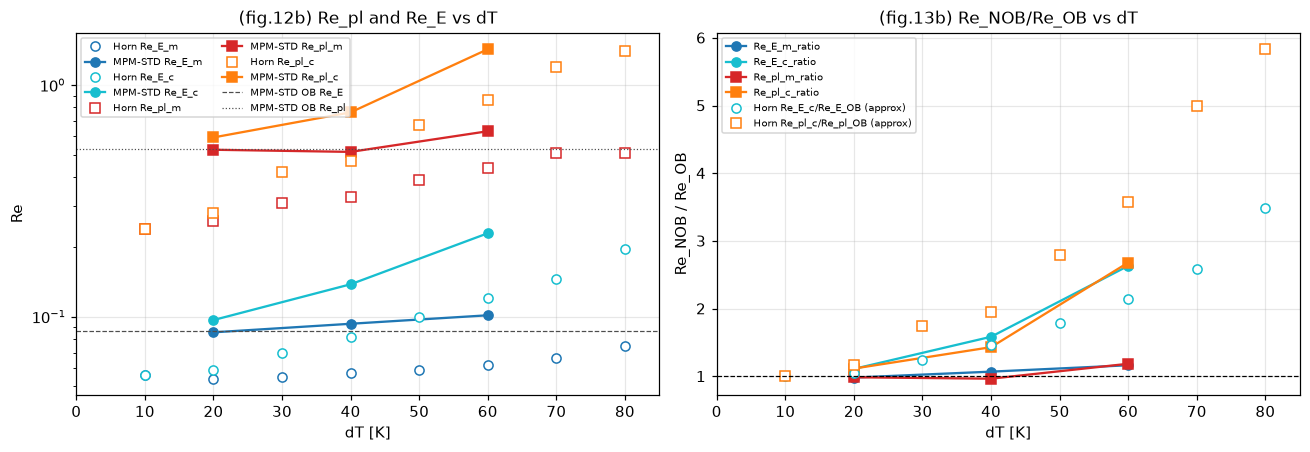

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for key, mk, c in (("Re_E_m", "o", "tab:blue"), ("Re_E_c", "o", "tab:cyan"), ("Re_pl_m", "s", "tab:red"), ("Re_pl_c", "s", "tab:orange")):
    ax[0].semilogy(horn["deltaT"], horn[key], mk, mfc="white", color=c, label=f"Horn {key}")
    ax[0].semilogy(dTs, col(key), mk + "-", color=c, label=f"MPM-STD {key}")
if ob:
    ax[0].axhline(ob["h"]["Re_E_m"], color="0.3", lw=0.8, ls="--", label="MPM-STD OB Re_E")
    if ob_ext and ob_ext["h"].get("Re_pl_m"): ax[0].axhline(ob_ext["h"]["Re_pl_m"], color="0.3", lw=0.8, ls=":", label="MPM-STD OB Re_pl")
ax[0].set_xlabel("dT [K]"); ax[0].set_ylabel("Re"); ax[0].set_xlim(0, 85); ax[0].legend(ncol=2, fontsize=6.5); ax[0].set_title("(fig.12b) Re_pl and Re_E vs dT")
for key, mk, c in (("Re_E_m_ratio", "o", "tab:blue"), ("Re_E_c_ratio", "o", "tab:cyan"), ("Re_pl_m_ratio", "s", "tab:red"), ("Re_pl_c_ratio", "s", "tab:orange")):
    ax[1].plot(dTs, col(key, "d"), mk + "-", color=c, label=key)
# Horn 의 비: csv 의 NOB 값 / OB 값(Horn OB Re_E ≈ 0.056 (dT→0 외삽), Re_pl ≈ 0.24) — 근사 참조
ax[1].plot(horn["deltaT"], horn["Re_E_c"] / 0.056, "o", mfc="white", color="tab:cyan", label="Horn Re_E_c/Re_E_OB (approx)")
ax[1].plot(horn["deltaT"], horn["Re_pl_c"] / 0.24, "s", mfc="white", color="tab:orange", label="Horn Re_pl_c/Re_pl_OB (approx)")
ax[1].axhline(1, color="k", lw=0.8, ls="--"); ax[1].set_xlabel("dT [K]"); ax[1].set_ylabel("Re_NOB / Re_OB"); ax[1].set_xlim(0, 85); ax[1].legend(fontsize=6.5); ax[1].set_title("(fig.13b) Re_NOB/Re_OB vs dT")
fig.tight_layout()
if SAVE_DIR: fig.savefig(f"{SAVE_DIR}/cv12_fig12_13.png", dpi=90)
plt.show()


## fig.14(b)·15(b) — Nu_NOB/Nu_OB = F_λ·F_Δ (4.32) 와 Nu vs ΔT

F_λ = 2λ_OB/(λ_t+λ_b), F_Δ = (κ_t Δ_t + κ_b Δ_b)/(κ_m Δ) (판 온도의 κ). 글리세롤은 κ 의 온도 의존이 약해 F_Δ ≈ 1, 비는 F_λ 가 결정.

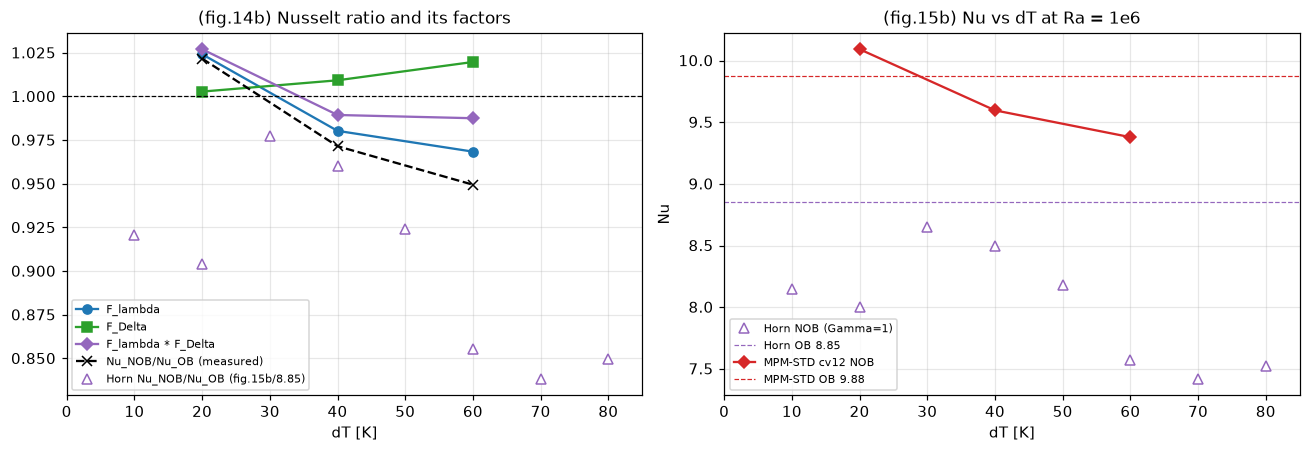

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(dTs, col("F_lambda", "d"), "o-", color="tab:blue", label="F_lambda")
ax[0].plot(dTs, col("F_Delta", "d"), "s-", color="tab:green", label="F_Delta")
ax[0].plot(dTs, col("F_lambda", "d") * col("F_Delta", "d"), "D-", color="tab:purple", label="F_lambda * F_Delta")
ax[0].plot(dTs, col("Nu_ratio", "d"), "x--", color="k", label="Nu_NOB/Nu_OB (measured)")
ax[0].plot(horn["deltaT"], horn["Nu_NOB"] / 8.85, "^", mfc="white", color="tab:purple", label="Horn Nu_NOB/Nu_OB (fig.15b/8.85)")
ax[0].axhline(1, color="k", lw=0.8, ls="--"); ax[0].set_xlabel("dT [K]"); ax[0].set_xlim(0, 85); ax[0].legend(fontsize=7); ax[0].set_title("(fig.14b) Nusselt ratio and its factors")
ax[1].plot(horn["deltaT"], horn["Nu_NOB"], "^", mfc="white", color="tab:purple", label="Horn NOB (Gamma=1)"); ax[1].axhline(8.85, color="tab:purple", lw=0.8, ls="--", label="Horn OB 8.85")
ax[1].plot(dTs, col("Nu_volume"), "D-", color="tab:red", label="MPM-STD cv12 NOB")
if ob: ax[1].axhline(ob["h"]["Nu_volume"], color="tab:red", lw=0.8, ls="--", label=f"MPM-STD OB {ob['h']['Nu_volume']:.2f}")
ax[1].set_xlabel("dT [K]"); ax[1].set_ylabel("Nu"); ax[1].set_xlim(0, 85); ax[1].legend(fontsize=7); ax[1].set_title("(fig.15b) Nu vs dT at Ra = 1e6")
fig.tight_layout()
if SAVE_DIR: fig.savefig(f"{SAVE_DIR}/cv12_fig14_15.png", dpi=90)
plt.show()


## 요약 표

In [10]:
hk = ("Nu_volume", "theta_c", "lambda_theta_b", "lambda_theta_t", "chi_lambda_theta", "lambda_u_b", "lambda_u_t", "chi_lambda_u", "Re_E_m", "Re_E_c", "Re_pl_m", "Re_pl_c", "T_rms_center")
print(f"{'case':22s}" + "".join(f"{k:>13s}" for k in hk))
for pr in ([ob] if ob else []) + runs:
    print(f"{pr['label']:22s}" + "".join(f"{pr['h'].get(k, float('nan')):13.4f}" for k in hk))


case                      Nu_volume      theta_clambda_theta_blambda_theta_tchi_lambda_theta   lambda_u_b   lambda_u_t chi_lambda_u       Re_E_m       Re_E_c      Re_pl_m      Re_pl_c T_rms_center
OB (rbc_ob)                  9.8779       0.0056       0.0500       0.0512       1.0253       0.1189       0.1223       1.0284       0.0870       0.0870          nan          nan       0.0372
dT=20K cv12                 10.0924       0.0868       0.0410       0.0578       1.4092       0.0876       0.1327       1.5145       0.0856       0.0967       0.5253       0.5937       0.0377
dT=40K cv12                  9.5966       0.1385       0.0377       0.0656       1.7387       0.0736       0.1547       2.1033       0.0932       0.1380       0.5142       0.7618       0.0336
dT=60K cv12                  9.3790       0.1939       0.0325       0.0720       2.2136       0.0580       0.1472       2.5373       0.1014       0.2291       0.6314       1.4263       0.0296
